# Inspect Pascal’s time-independent background models

This notebook explores the five version 3.00 normalizing-flow background models. We first inspect their metadata and domains; later we will examine their distributions and compare the relevant projection with Pascal’s reference.

The component-to-file mapping and the provenance of the stored rates remain to be verified. Loading a model does not validate its predictions.


In [1]:
%load_ext autoreload
%autoreload 2

## 1. Environment and imports

Check that the notebook uses the project environment with Pascal’s updated COSIpy.


In [2]:
import sys
print(sys.executable)

/Users/maura/Documents/COSI/cosi_background/cosipy-background-nf/.venv/bin/python


In [3]:
from pathlib import Path
from cosipy.background_estimation.ml import NFBackground
from astropy.io import fits
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import torch
import subprocess
import h5py

%matplotlib inline


WARNING FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.



In [4]:
import gzip
import shutil

## 2. Load the first model

Start with part 01 to inspect one model before loading all five. The physical component associated with this file is provisional.


In [5]:
model_path = Path("../model/nfbackground_part-01_v3-00.fits")

print("File exists:", model_path.exists())

background = NFBackground(
    model_path,
    devices=["cpu"],
    density_compile_mode=None,
    show_progress=False,
)

print("Model version:", background._version)

File exists: True
Model version: 3.00


## 3. Inspect part 01 metadata

The checkpoint contains the density configuration and the input for the constant-rate model. `_ckpt` is an internal COSIpy attribute, used here for inspection.


In [6]:
print("Density configuration keys:")
print(background._ckpt["density_input"].keys())

print("\nRate input:")
print(background._ckpt["rate_input"])

Density configuration keys:
dict_keys(['model_state_dict', 'bins', 'hidden_units', 'residual_blocks', 'total_layers', 'menergy_cuts', 'phi_cuts', 'coefficients'])

Rate input:
{'counts': 97554902, 'livetime': np.float64(6579555.0)}


The energy and Phi cuts define the model domain. The constant rate is calculated from the stored counts and livetime; their provenance and selection must be checked before using the rate as a component weight. The density configuration’s `bins` parameter is internal to the normalizing flow, not CDS analysis binning.


In [7]:
density_input = background._ckpt["density_input"]
rate_input = background._ckpt["rate_input"]

print("Measured-energy limits:", density_input["menergy_cuts"], "keV")
print("Phi limits:", density_input["phi_cuts"], "radians")
print("Constant rate:", rate_input["counts"] / rate_input["livetime"], "events/s")

Measured-energy limits: [100, 10000] keV
Phi limits: [0.0, 3.141592653589793] radians
Constant rate: 14.826975684525777 events/s


## 4. Inspect all five models

Load each file separately and compare its version, domain, counts, livetime, and constant rate. The models are stored in `models` for later exploration; no component weights or combined prediction are assumed.


In [8]:
models = {}

for part in range(1, 6):
    model_path = Path(f"../model/nfbackground_part-{part:02d}_v3-00.fits")

    model = NFBackground(
        model_path,
        devices=["cpu"],
        density_compile_mode=None,
        show_progress=False,
    )

    models[part] = model

    density = model._ckpt["density_input"]
    rate = model._ckpt["rate_input"]

    print(f"\nPart {part:02d}")
    print(f"  Version: {model._version}")
    print(f"  Energy limits: {density['menergy_cuts']} keV")
    print(f"  Phi limits: {density['phi_cuts']} radians")
    print(f"  Counts: {rate['counts']:,}")
    print(f"  Livetime: {rate['livetime']:,.0f} s")
    print(f"  Constant rate: {rate['counts'] / rate['livetime']:.3f} events/s")


Part 01
  Version: 3.00
  Energy limits: [100, 10000] keV
  Phi limits: [0.0, 3.141592653589793] radians
  Counts: 97,554,902
  Livetime: 6,579,555 s
  Constant rate: 14.827 events/s

Part 02
  Version: 3.00
  Energy limits: [100, 10000] keV
  Phi limits: [0.0, 3.141592653589793] radians
  Counts: 27,081,364
  Livetime: 6,579,555 s
  Constant rate: 4.116 events/s

Part 03
  Version: 3.00
  Energy limits: [100, 10000] keV
  Phi limits: [0.0, 3.141592653589793] radians
  Counts: 6,176,355
  Livetime: 6,579,555 s
  Constant rate: 0.939 events/s

Part 04
  Version: 3.00
  Energy limits: [100, 10000] keV
  Phi limits: [0.0, 3.141592653589793] radians
  Counts: 25,705,670
  Livetime: 6,579,555 s
  Constant rate: 3.907 events/s

Part 05
  Version: 3.00
  Energy limits: [100, 10000] keV
  Phi limits: [0.0, 3.141592653589793] radians
  Counts: 4,958,885
  Livetime: 6,579,555 s
  Constant rate: 0.754 events/s


## 5. Component 01: candidate EGB photons

Compare the simulated cosmic-photon events with the part 01 model. The file-to-component mapping remains provisional.


### 5.1. Simulated cosmic-photon background

Inspect the candidate reference event file and its columns, then build a normalized measured-energy and scattering-angle projection. The matching event count supports the proposed correspondence with part 01 but does not establish its training provenance.


In [9]:
egb_path = Path(
    "../data/background_components/"
    "CosmicPhotons_3months_unbinned_data_filtered_with_SAAcut.fits.gz"
)

print("File exists:", egb_path.exists())

File exists: True


#### Prepare and check the uncompressed file

Use the existing uncompressed file when available and check that the FITS table fits within it before histogramming. A size check does not verify all event values.


In [10]:
egb_uncompressed_path = egb_path.with_suffix("")

print("Uncompressed file exists:", egb_uncompressed_path.exists())

Uncompressed file exists: True


In [11]:
if egb_uncompressed_path.exists():
    print("Using existing file:", egb_uncompressed_path)
else:
    with gzip.open(egb_path, "rb") as compressed:
        with egb_uncompressed_path.open("xb") as uncompressed:
            shutil.copyfileobj(compressed, uncompressed, length=1024 * 1024)

    print("Created:", egb_uncompressed_path)

Using existing file: ../data/background_components/CosmicPhotons_3months_unbinned_data_filtered_with_SAAcut.fits


In [12]:
with fits.open(egb_uncompressed_path, memmap=True) as hdul:
    hdul.info()

    table_info = hdul.fileinfo(1)
    expected_end = table_info["datLoc"] + table_info["datSpan"]
    actual_size = egb_uncompressed_path.stat().st_size

    print(f"\nFile size: {actual_size:,} bytes")
    print(f"End of FITS table: {expected_end:,} bytes")
    print("Table fits within file:", actual_size >= expected_end)

if actual_size < expected_end:
    raise ValueError("The uncompressed FITS table is incomplete.")


Filename: ../data/background_components/CosmicPhotons_3months_unbinned_data_filtered_with_SAAcut.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU       4   ()      
  1                1 BinTableHDU     45   97554902R x 11C   [D, D, 2D, 2D, 2D, D, D, D, D, D, D]   

File size: 10,926,158,400 bytes
End of FITS table: 10,926,158,400 bytes
Table fits within file: True


In [13]:
with fits.open(egb_uncompressed_path, memmap=True) as hdul:
    print(hdul[1].columns)

ColDefs(
    name = 'Energies'; format = 'D'; unit = 'keV'
    name = 'TimeTags'; format = 'D'; unit = 's'
    name = 'Xpointings (glon,glat)'; format = '2D'; unit = 'rad'; dim = '(2)'
    name = 'Ypointings (glon,glat)'; format = '2D'; unit = 'rad'; dim = '(2)'
    name = 'Zpointings (glon,glat)'; format = '2D'; unit = 'rad'; dim = '(2)'
    name = 'Phi'; format = 'D'; unit = 'rad'
    name = 'Chi local'; format = 'D'; unit = 'rad'
    name = 'Psi local'; format = 'D'; unit = 'rad'
    name = 'Distance'; format = 'D'; unit = 'cm'
    name = 'Chi galactic'; format = 'D'; unit = 'deg'
    name = 'Psi galactic'; format = 'D'; unit = 'deg'
)


#### Build the simulation projection

Read the uncompressed table in chunks and count events in measured-energy and scattering-angle bins. All events in the file are included without a time selection, so the result is integrated over the file’s observation period. The bins are exploratory; Pascal’s exact plot binning has not been confirmed.


In [14]:
energy_edges = np.geomspace(509,513, 1001)  # keV
line_window = (509, 513)                         # keV, COSI 511 keV bin
phi_edges = np.linspace(0, 180, 361)           # degrees

egb_counts = np.zeros(
    (len(energy_edges) - 1, len(phi_edges) - 1),
    dtype=np.int64,
)

chunk_size = 1_000_000

with fits.open(egb_uncompressed_path, memmap=True) as hdul:
    events = hdul[1].data
    n_events = len(events)

    for start in range(0, n_events, chunk_size):
        chunk = events[start:start + chunk_size]

        counts, _, _ = np.histogram2d(
            chunk["Energies"],
            np.rad2deg(chunk["Phi"]),
            bins=(energy_edges, phi_edges),
        )
        egb_counts += counts.astype(np.int64)

print(f"Events in file: {n_events:,}")
print(f"Events in histogram: {egb_counts.sum():,}")
print(f"Events outside histogram: {n_events - egb_counts.sum():,}")

Events in file: 97,554,902
Events in histogram: 162,675
Events outside histogram: 97,392,227


#### Plot the normalized simulation

Normalize by the event total and bin area to show a probability density in keV⁻¹ deg⁻¹. Empty bins and values at the low end of the color scale are both shown in dark purple; the display does not alter the counts.


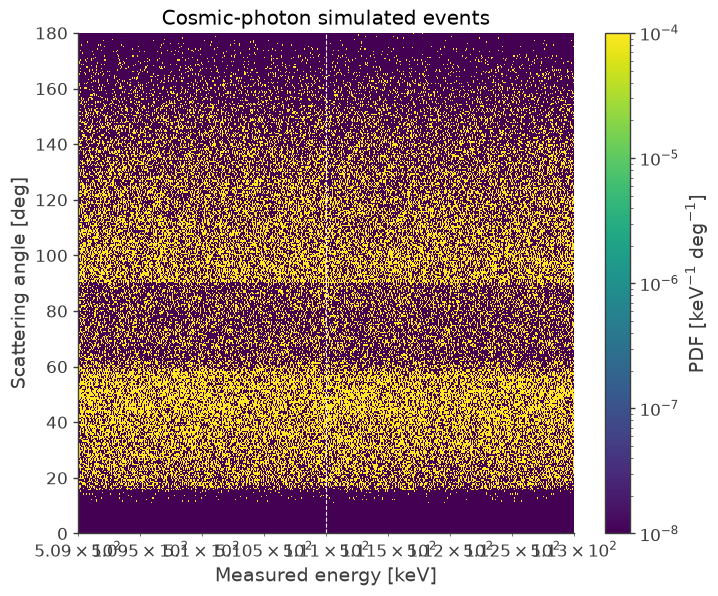

In [15]:
bin_areas = np.diff(energy_edges)[:, None] * np.diff(phi_edges)[None, :]
egb_density = egb_counts / egb_counts.sum() / bin_areas

fig, ax = plt.subplots(figsize=(8, 6.5))

cmap = plt.colormaps["viridis"].copy()
cmap.set_bad(cmap(0))
mesh = ax.pcolormesh(
    energy_edges,
    phi_edges,
    egb_density.T,
    norm=LogNorm(vmin=1e-8, vmax=1e-4),
    cmap=cmap,
    shading="auto",
)

ax.set_xscale("log")
ax.axvline(511, color="white", lw=0.8, ls="--")  # 511 keV window
ax.set_xlabel("Measured energy [keV]")
ax.set_ylabel("Scattering angle [deg]")
ax.set_title("Cosmic-photon simulated events")

fig.colorbar(mesh, ax=ax, label=r"PDF [keV$^{-1}$ deg$^{-1}$]")


### 5.2. Normalizing-flow background: component 01

The small sampling test below launches [the sampling script](../src/sample_time_independent_background.py) in a separate process to protect the notebook kernel from COSIpy multiprocessing. A full-size component 01 sample is generated separately from the terminal; do not read it until sampling has finished and its completed count has been checked.

The NF describes a continuous, time-independent CDS shape. Next we will histogram its sampled measured energy and scattering angle using the simulation’s bin edges. Sampling precision depends on sample size. Expected counts require a suitable normalization and livetime; the part 01 to cosmic-photon mapping remains provisional.


#### Check the full component 01 sample

Use the full sample only if its completed count matches the requested count and it was drawn from the part 01 model.

In [16]:
nf_path = Path("../data/NF_background/part-01_full_caffeinated.hdf5")

with h5py.File(nf_path, "r") as sample_file:
    attrs = dict(sample_file.attrs)
    n_nf = sample_file["Energies"].shape[0]

for key, value in attrs.items():
    print(f"{key}: {value}")

if (
    attrs.get("part") != 1
    or attrs.get("completed_samples") != attrs.get("requested_samples")
    or attrs.get("completed_samples") != n_nf
):
    raise ValueError("The NF sample is incomplete or does not belong to part 01.")

completed_samples: 97554902
description: Time-independent NF shape samples; no physical times or rate normalization
model_file: nfbackground_part-01_v3-00.fits
model_version: 3.00
part: 1
requested_samples: 97554902


#### Build the NF projection

Histogram the sampled measured energy and scattering angle in chunks, using the same bin edges as the simulation.

In [17]:
nf_counts = np.zeros_like(egb_counts)

with h5py.File(nf_path, "r") as sample_file:
    energies = sample_file["Energies"]
    phis = sample_file["Phi"]

    for start in range(0, n_nf, chunk_size):
        stop = min(start + chunk_size, n_nf)

        counts, _, _ = np.histogram2d(
            energies[start:stop],
            np.rad2deg(phis[start:stop]),
            bins=(energy_edges, phi_edges),
        )
        nf_counts += counts.astype(np.int64)

print(f"Samples in file: {n_nf:,}")
print(f"Samples in histogram: {nf_counts.sum():,}")
print(f"Samples outside histogram: {n_nf - nf_counts.sum():,}")

Samples in file: 97,554,902
Samples in histogram: 161,588
Samples outside histogram: 97,393,314


#### Plot the normalized NF sample

Apply the same normalization and color scale as the simulation plot.

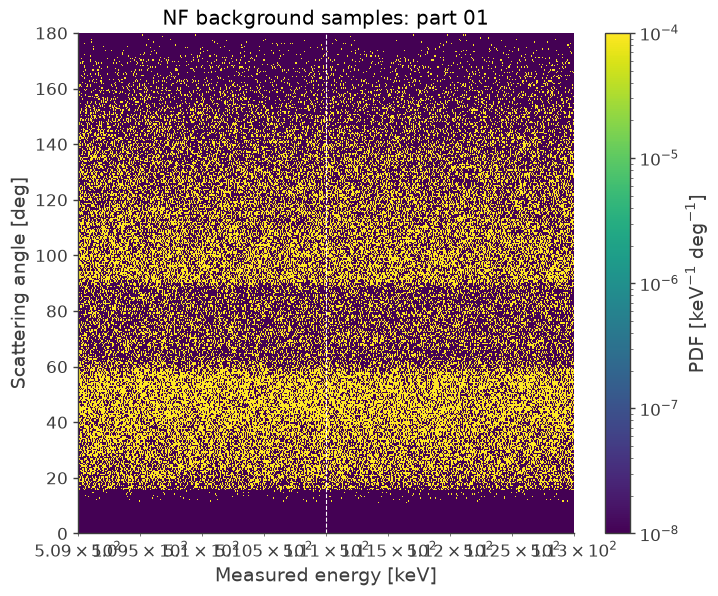

In [18]:
nf_density = nf_counts / nf_counts.sum() / bin_areas

fig, ax = plt.subplots(figsize=(8, 6.5))

mesh = ax.pcolormesh(
    energy_edges,
    phi_edges,
    nf_density.T,
    norm=LogNorm(vmin=1e-8, vmax=1e-4),
    cmap=cmap,
    shading="auto",
)

ax.set_xscale("log")
ax.axvline(511, color="white", lw=0.8, ls="--")  # 511 keV window
ax.set_xlabel("Measured energy [keV]")
ax.set_ylabel("Scattering angle [deg]")
ax.set_title("NF background samples: part 01")

fig.colorbar(mesh, ax=ax, label=r"PDF [keV$^{-1}$ deg$^{-1}$]")

#### Compare simulation and NF side by side

Both panels share the bins, normalization, and color scale.

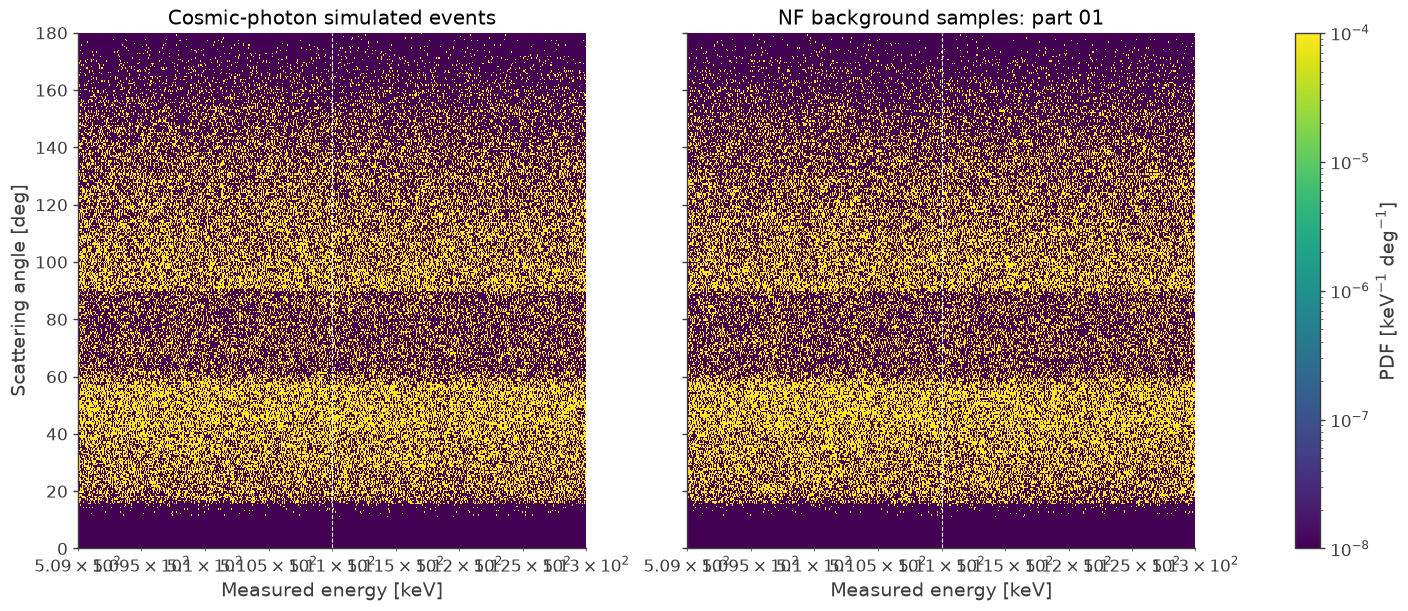

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True, layout="constrained")

panels = [
    (egb_density, "Cosmic-photon simulated events"),
    (nf_density, "NF background samples: part 01"),
]

for ax, (density, title) in zip(axes, panels):
    mesh = ax.pcolormesh(
        energy_edges,
        phi_edges,
        density.T,
        norm=LogNorm(vmin=1e-8, vmax=1e-4),
        cmap=cmap,
        shading="auto",
    )
    ax.set_xscale("log")
    ax.axvline(511, color="white", lw=0.8, ls="--")  # 511 keV window
    ax.set_xlabel("Measured energy [keV]")
    ax.set_title(title)

axes[0].set_ylabel("Scattering angle [deg]")

fig.colorbar(mesh, ax=axes, label=r"PDF [keV$^{-1}$ deg$^{-1}$]")

#### Compare the 511 keV window

In the 509–513 keV window the distribution barely changes with energy, so a 2D map shows mostly noise. Compare instead the scattering-angle distribution of the events in that window. Both are normalized to unit area; the lower panel shows the NF / simulation ratio with Poisson errors.

In [20]:
def phi_in_window(read_chunk, n_total, edges):
    """Histogram Phi [deg] for events whose energy lies inside line_window."""
    counts = np.zeros(len(edges) - 1, dtype=np.int64)
    for start in range(0, n_total, chunk_size):
        energy, phi = read_chunk(start, min(start + chunk_size, n_total))
        in_window = (energy >= line_window[0]) & (energy < line_window[1])
        counts += np.histogram(np.rad2deg(phi[in_window]), bins=edges)[0]
    return counts


window_phi_edges = np.linspace(0, 180, 91)  # 2 degree bins

with fits.open(egb_uncompressed_path, memmap=True) as hdul:
    events = hdul[1].data
    egb_window_counts = phi_in_window(
        lambda a, b: (events["Energies"][a:b], events["Phi"][a:b]),
        len(events),
        window_phi_edges,
    )

with h5py.File(nf_path, "r") as sample_file:
    nf_window_counts = phi_in_window(
        lambda a, b: (sample_file["Energies"][a:b], sample_file["Phi"][a:b]),
        n_nf,
        window_phi_edges,
    )

print(f"Simulated events in {line_window} keV: {egb_window_counts.sum():,}")
print(f"NF samples in {line_window} keV: {nf_window_counts.sum():,}")

Simulated events in (509, 513) keV: 162,652
NF samples in (509, 513) keV: 161,582


Text(0, 0.5, 'NF / sim')

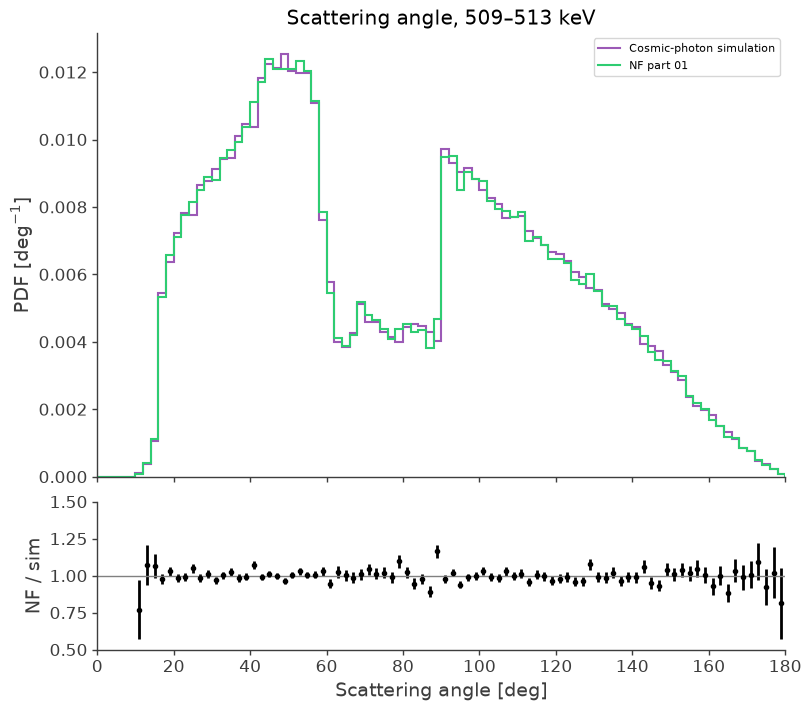

In [21]:
phi_widths = np.diff(window_phi_edges)
phi_centers = 0.5 * (window_phi_edges[:-1] + window_phi_edges[1:])

egb_pdf = egb_window_counts / egb_window_counts.sum() / phi_widths
nf_pdf = nf_window_counts / nf_window_counts.sum() / phi_widths

with np.errstate(divide="ignore", invalid="ignore"):
    ratio = nf_pdf / egb_pdf
    ratio_err = ratio * np.sqrt(1 / nf_window_counts + 1 / egb_window_counts)

fig, (ax, ax_ratio) = plt.subplots(
    2, 1, figsize=(8, 7), sharex=True,
    gridspec_kw={"height_ratios": [3, 1]}, layout="constrained",
)

ax.stairs(egb_pdf, window_phi_edges, label="Cosmic-photon simulation", lw=1.5)
ax.stairs(nf_pdf, window_phi_edges, label="NF part 01", lw=1.5)
ax.set_ylabel(r"PDF [deg$^{-1}$]")
ax.set_title(f"Scattering angle, {line_window[0]}–{line_window[1]} keV")
ax.legend()

ax_ratio.errorbar(phi_centers, ratio, yerr=ratio_err, fmt="o", ms=3, color="k")
ax_ratio.axhline(1, color="gray", lw=1)
ax_ratio.set_ylim(0.5, 1.5)
ax_ratio.set_xlim(0, 180)
ax_ratio.set_xlabel("Scattering angle [deg]")
ax_ratio.set_ylabel("NF / sim")

### 5.3. Compare time slices of the simulation with the NF

The NF has no time dependence: it is one fixed distribution. Here we cut slices of the simulation by `TimeTags` and compare each slice with that same NF.

Slices are given in hours since the first simulated event. One hour holds about 41,000 events, so the maps use coarser bins than above: 100 logarithmic energy bins and 2° in scattering angle. This section uses its own 100–10,000 keV grid, independent of the bins chosen in 5.1; the NF map is the full sample histogrammed on that grid. Each map is normalized to unit area, so only the shapes are compared.

In [22]:
time_slices_h = [(15, 16), (20, 21)]  # hours since the first event; edit freely

# Own grid for this section, independent of the bins chosen in 5.1.
slice_energy_edges = np.geomspace(100, 10_000, 101)  # keV
slice_phi_edges = np.linspace(0, 180, 91)            # degrees
slice_bin_areas = np.diff(slice_energy_edges)[:, None] * np.diff(slice_phi_edges)[None, :]

# NF reference on the same grid, from the full sample.
nf_slice_counts = np.zeros((len(slice_energy_edges) - 1, len(slice_phi_edges) - 1), dtype=np.int64)
with h5py.File(nf_path, "r") as sample_file:
    for start in range(0, n_nf, chunk_size):
        stop = min(start + chunk_size, n_nf)
        nf_slice_counts += np.histogram2d(
            sample_file["Energies"][start:stop],
            np.rad2deg(sample_file["Phi"][start:stop]),
            bins=(slice_energy_edges, slice_phi_edges),
        )[0].astype(np.int64)

print(f"NF samples on the slice grid: {nf_slice_counts.sum():,} of {n_nf:,}")

NF samples on the slice grid: 97,554,902 of 97,554,902


In [23]:
slice_counts = {
    s: np.zeros((len(slice_energy_edges) - 1, len(slice_phi_edges) - 1), dtype=np.int64)
    for s in time_slices_h
}

with fits.open(egb_uncompressed_path, memmap=True) as hdul:
    events = hdul[1].data
    t0 = events["TimeTags"].min()

    # TimeTags are not sorted, so every chunk is checked against every slice.
    for start in range(0, len(events), chunk_size):
        chunk = events[start:start + chunk_size]
        hours = (chunk["TimeTags"] - t0) / 3600

        for (h_start, h_stop), counts in slice_counts.items():
            sel = (hours >= h_start) & (hours < h_stop)
            counts += np.histogram2d(
                chunk["Energies"][sel],
                np.rad2deg(chunk["Phi"][sel]),
                bins=(slice_energy_edges, slice_phi_edges),
            )[0].astype(np.int64)

for (h_start, h_stop), counts in slice_counts.items():
    print(f"Hours {h_start}-{h_stop}: {counts.sum():,} events")

Hours 15-16: 45,398 events
Hours 20-21: 39,022 events


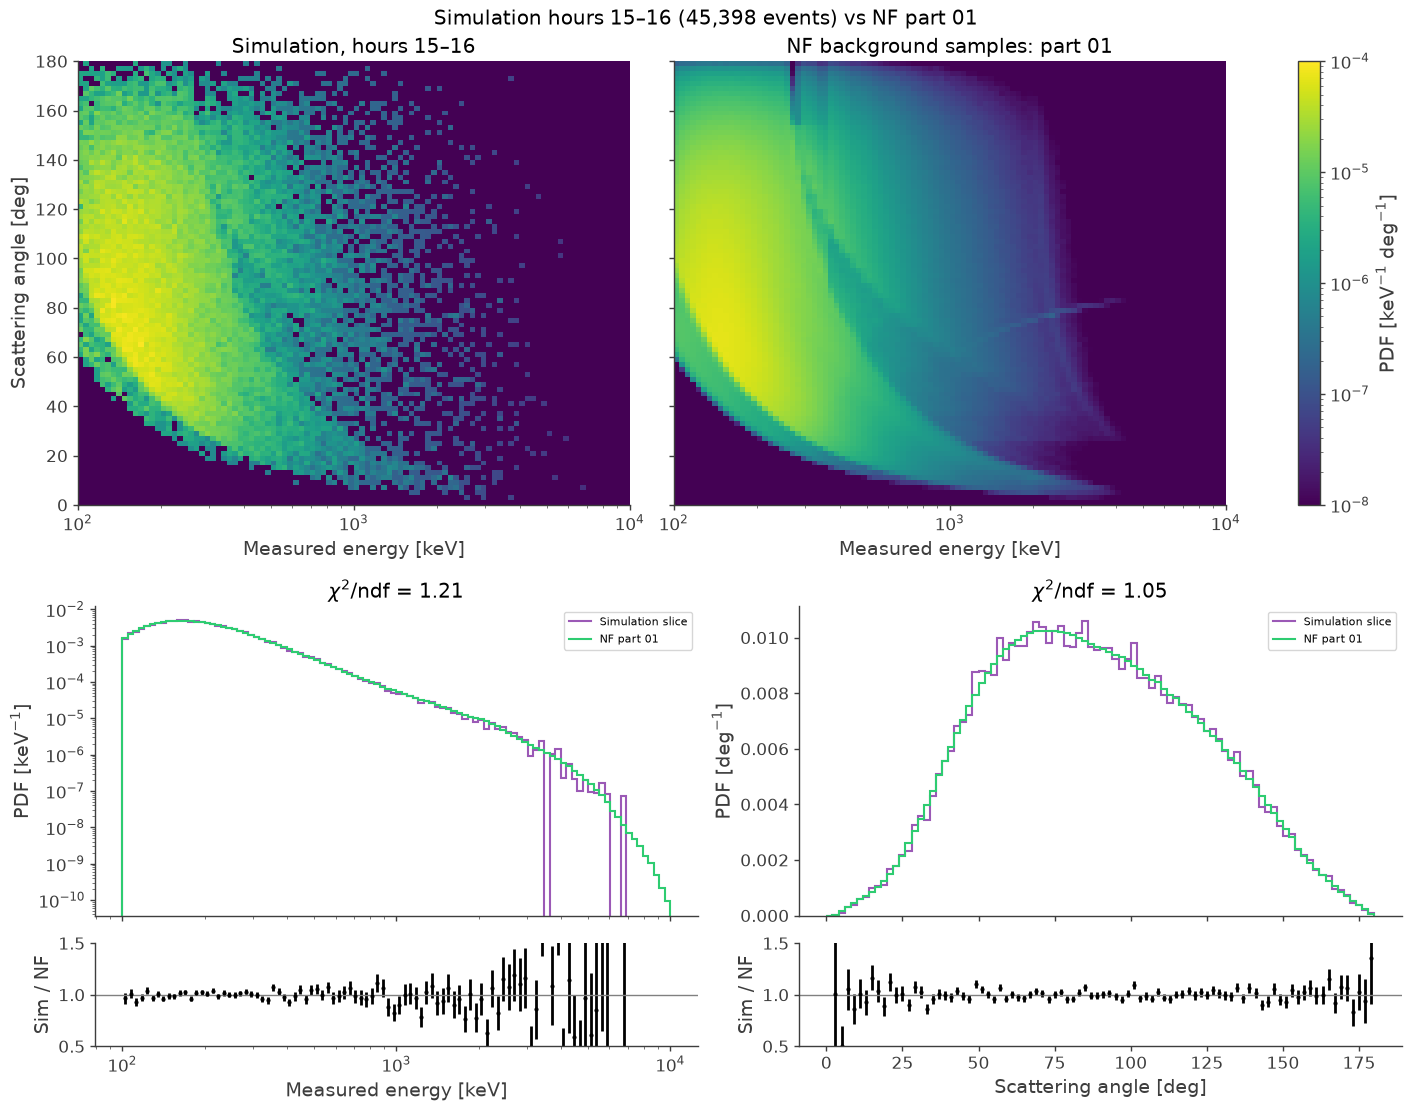

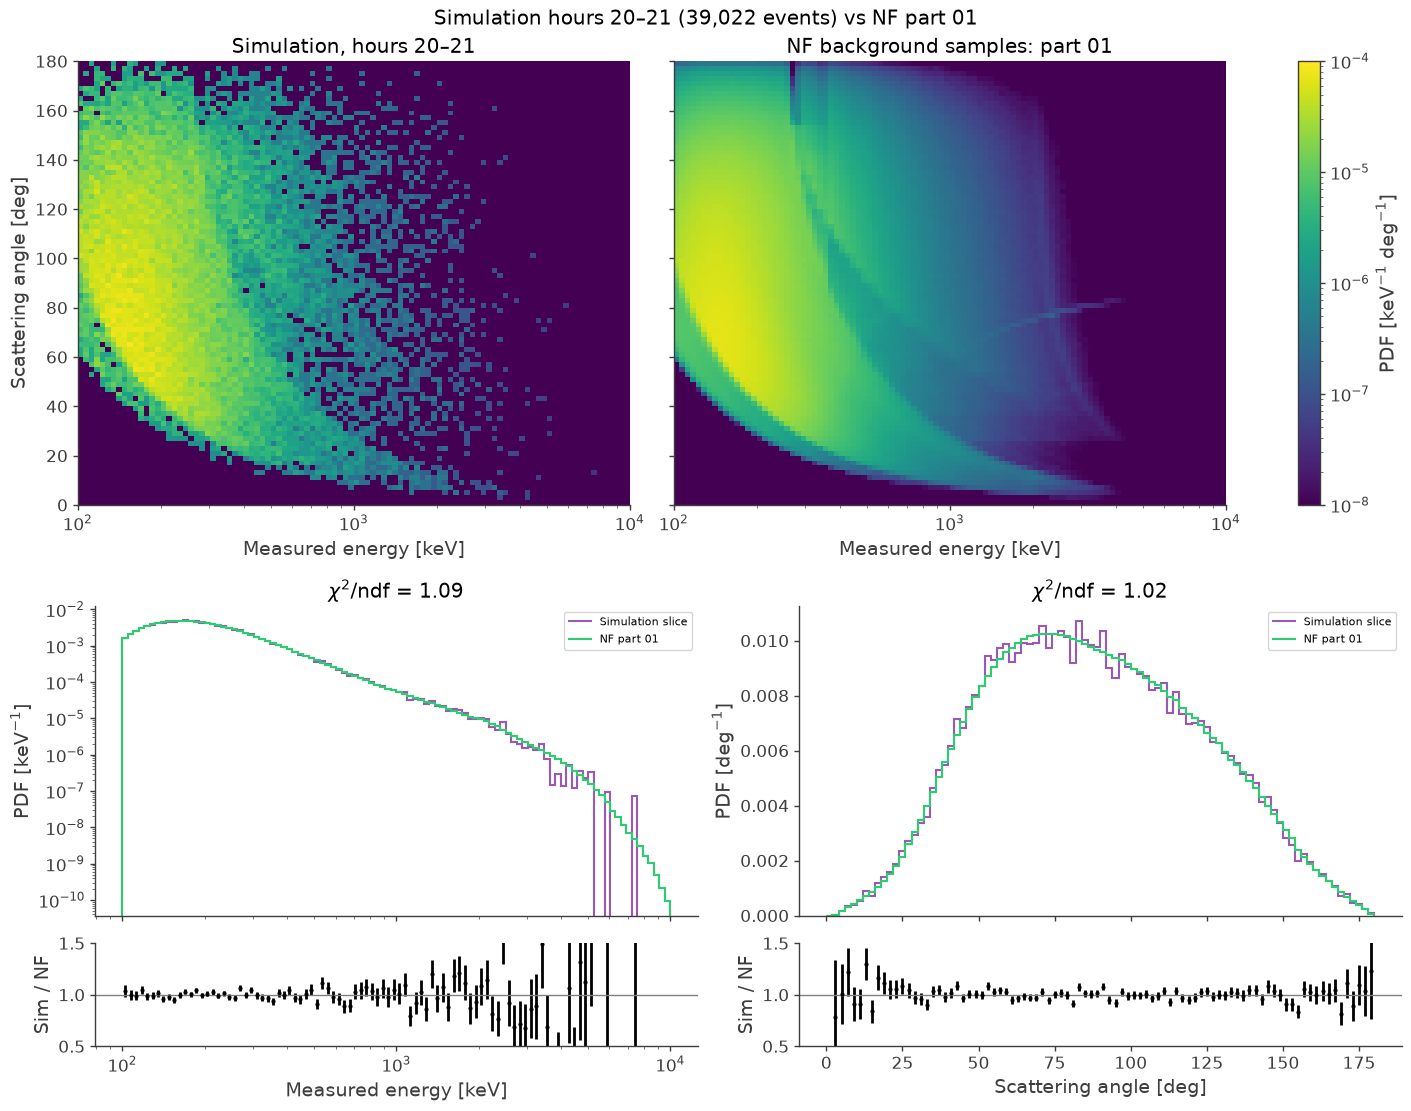

In [24]:
def shape_chi2(counts, reference, min_expected=5):
    """Pearson chi2/ndf of counts against the reference shape, scaled to the same total."""
    expected = counts.sum() * reference / reference.sum()
    use = expected >= min_expected
    return ((counts[use] - expected[use]) ** 2 / expected[use]).sum() / (use.sum() - 1)


def compare_profile(ax, ax_ratio, sim, nf, edges, xlabel, ylabel):
    """Overlay normalized 1D profiles and plot their ratio with Poisson errors."""
    widths = np.diff(edges)
    centers = 0.5 * (edges[:-1] + edges[1:])
    sim_pdf = sim / sim.sum() / widths
    nf_pdf = nf / nf.sum() / widths
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = sim_pdf / nf_pdf
        ratio_err = ratio / np.sqrt(sim)

    ax.stairs(sim_pdf, edges, label="Simulation slice", lw=1.5)
    ax.stairs(nf_pdf, edges, label="NF part 01", lw=1.5)
    ax.set_ylabel(ylabel)
    ax.set_title(rf"$\chi^2$/ndf = {shape_chi2(sim, nf):.2f}")
    ax.legend()
    ax_ratio.errorbar(centers, ratio, yerr=ratio_err, fmt="o", ms=2, color="k")
    ax_ratio.axhline(1, color="gray", lw=1)
    ax_ratio.set_ylim(0.5, 1.5)
    ax_ratio.set_xlabel(xlabel)
    ax_ratio.set_ylabel("Sim / NF")


nf_slice_density = nf_slice_counts / nf_slice_counts.sum() / slice_bin_areas

for (h_start, h_stop), counts in slice_counts.items():
    fig = plt.figure(figsize=(14, 11), layout="constrained")
    top, bottom = fig.subfigures(2, 1, height_ratios=[1, 1])
    fig.suptitle(f"Simulation hours {h_start}–{h_stop} ({counts.sum():,} events) vs NF part 01")

    # 2D maps side by side
    map_axes = top.subplots(1, 2, sharey=True)
    density = counts / counts.sum() / slice_bin_areas
    for ax, (d, title) in zip(map_axes, [(density, f"Simulation, hours {h_start}–{h_stop}"),
                                         (nf_slice_density, "NF background samples: part 01")]):
        mesh = ax.pcolormesh(
            slice_energy_edges, slice_phi_edges, d.T,
            norm=LogNorm(vmin=1e-8, vmax=1e-4), cmap=cmap, shading="auto",
        )
        ax.set_xscale("log")
        ax.set_xlabel("Measured energy [keV]")
        ax.set_title(title)
    map_axes[0].set_ylabel("Scattering angle [deg]")
    top.colorbar(mesh, ax=map_axes, label=r"PDF [keV$^{-1}$ deg$^{-1}$]")

    # 1D projections: energy and scattering angle
    prof_axes = bottom.subplots(2, 2, sharex="col", gridspec_kw={"height_ratios": [3, 1]})
    compare_profile(
        prof_axes[0, 0], prof_axes[1, 0],
        counts.sum(axis=1), nf_slice_counts.sum(axis=1), slice_energy_edges,
        "Measured energy [keV]", r"PDF [keV$^{-1}$]",
    )
    prof_axes[0, 0].set_xscale("log")
    prof_axes[0, 0].set_yscale("log")
    compare_profile(
        prof_axes[0, 1], prof_axes[1, 1],
        counts.sum(axis=0), nf_slice_counts.sum(axis=0), slice_phi_edges,
        "Scattering angle [deg]", r"PDF [deg$^{-1}$]",
    )
    plt.show()